# Probabilistic Matrix Factorization with Alternating Least Squares (ALS)
### Practicals 1 to 5 on the MovieLens-32M Dataset

We import the required libraries and set the dataset paths and random seed.

In [1]:
import os
import csv
import time
import array as arr
import pickle as pkl
from typing import Dict, Any, Tuple, List

import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

DATASET_CSV_PATH = "ratings.csv"
MOVIES_CSV_PATH = "movies.csv"
DATASET_PATH = "dataset.pkl"
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print(f"Configuration set. Target dataset: {DATASET_PATH}")

Configuration set. Target dataset: dataset.pkl


---
# Practical 1: Data Parsing and Exploration

### 1.1 Dual-Indexed Data Structure (by User and by Movie)
We define `parsefile` to parse `ratings.csv` into a dual Compressed Sparse Row (CSR) data structure indexed both by user (`users_offsets`, `users_movies`, `users_ratings`) and by movie (`movies_offsets`, `movies_users`, `movies_ratings`).

In [2]:
def parsefile(filename: str, label_func=lambda u, m, t: 1 if np.random.random() < 0.8 else 0) -> Dict[str, Any]:
    """Parses MovieLens CSV into a dual CSR data structure indexed by user and by movie."""
    user_index = {}
    movie_index = {}

    user_ids_mapped = arr.array("I")
    movie_ids_mapped = arr.array("I")
    ratings_mapped = arr.array("B")  # Half-star units (1..10)
    labels = arr.array("B")

    user_counts = []
    movie_counts = []

    with open(filename, "r", encoding="utf-8", buffering=4 * 1024 * 1024) as f:
        f.readline()  # Skip header
        for line in f:
            row = line.rstrip().split(",")
            if len(row) < 3:
                continue
            u_str, m_str, r_str, tmstp = row[0], row[1], row[2], row[3]

            u_id = user_index.get(u_str)
            if u_id is None:
                u_id = len(user_index)
                user_index[u_str] = u_id
                user_counts.append(0)

            m_id = movie_index.get(m_str)
            if m_id is None:
                m_id = len(movie_index)
                movie_index[m_str] = m_id
                movie_counts.append(0)

            user_ids_mapped.append(u_id)
            movie_ids_mapped.append(m_id)
            ratings_mapped.append(int(2 * float(r_str)))
            labels.append(label_func(u_id, m_id, tmstp))

            user_counts[u_id] += 1
            movie_counts[m_id] += 1

    num_users = len(user_index)
    num_movies = len(movie_index)
    num_ratings = len(ratings_mapped)

    users_offsets = arr.array("I", [0] * (num_users + 1))
    movies_offsets = arr.array("I", [0] * (num_movies + 1))

    acc = 0
    for i in range(num_users):
        acc += user_counts[i]
        users_offsets[i + 1] = acc

    acc = 0
    for i in range(num_movies):
        acc += movie_counts[i]
        movies_offsets[i + 1] = acc

    users_movies = arr.array("I", [0] * num_ratings)
    users_ratings = arr.array("B", [0] * num_ratings)
    users_labels = arr.array("B", [0] * num_ratings)

    movies_users = arr.array("I", [0] * num_ratings)
    movies_ratings = arr.array("B", [0] * num_ratings)
    movies_labels = arr.array("B", [0] * num_ratings)

    user_positions = list(users_offsets[:-1])
    movie_positions = list(movies_offsets[:-1])

    for i in range(num_ratings):
        u = user_ids_mapped[i]
        m = movie_ids_mapped[i]
        r = ratings_mapped[i]
        l = labels[i]

        u_pos = user_positions[u]
        users_movies[u_pos] = m
        users_ratings[u_pos] = r
        users_labels[u_pos] = l
        user_positions[u] += 1

        m_pos = movie_positions[m]
        movies_users[m_pos] = u
        movies_ratings[m_pos] = r
        movies_labels[m_pos] = l
        movie_positions[m] += 1

    user_index_rev = [None] * num_users
    for k, v in user_index.items():
        user_index_rev[v] = k

    movie_index_rev = [None] * num_movies
    for k, v in movie_index.items():
        movie_index_rev[v] = k

    return {
        "users_index": user_index, "users_index_rev": user_index_rev,
        "users_ratings": users_ratings, "users_offsets": users_offsets,
        "users_movies": users_movies, "users_labels": users_labels,
        "movies_index": movie_index, "movies_index_rev": movie_index_rev,
        "movies_ratings": movies_ratings, "movies_offsets": movies_offsets,
        "movies_users": movies_users, "movies_labels": movies_labels,
    }


def load_dataset(filename: str) -> Dict[str, Any]:
    with open(filename, "rb") as f:
        return pkl.load(f)

We parse `ratings.csv` (or load `dataset.pkl` if already parsed) and inspect the summary statistics.

In [3]:
t0 = time.perf_counter()
if not os.path.exists(DATASET_PATH):
    print("Parsing CSV file...")
    dataset = parsefile(DATASET_CSV_PATH)
    with open(DATASET_PATH, "wb") as f:
        pkl.dump(dataset, f)
    print(f"Parsed and saved to {DATASET_PATH} in {time.perf_counter() - t0:.2f}s.")
else:
    print(f"Loading {DATASET_PATH}...")
    dataset = load_dataset(DATASET_PATH)
    print(f"Loaded in {time.perf_counter() - t0:.2f}s.")

n_users = len(dataset["users_index"])
n_movies = len(dataset["movies_index"])
n_ratings = len(dataset["users_ratings"])

print(f"Unique Users:  {n_users:,}")
print(f"Unique Movies: {n_movies:,}")
print(f"Total Ratings: {n_ratings:,}")

Loading dataset.pkl...
Loaded in 2.92s.
Unique Users:  200,948
Unique Movies: 84,432
Total Ratings: 32,000,204


### 1.2 Rating Distribution
We compute the frequency of each star rating value ($0.5$ to $5.0$) and plot the empirical rating distribution.

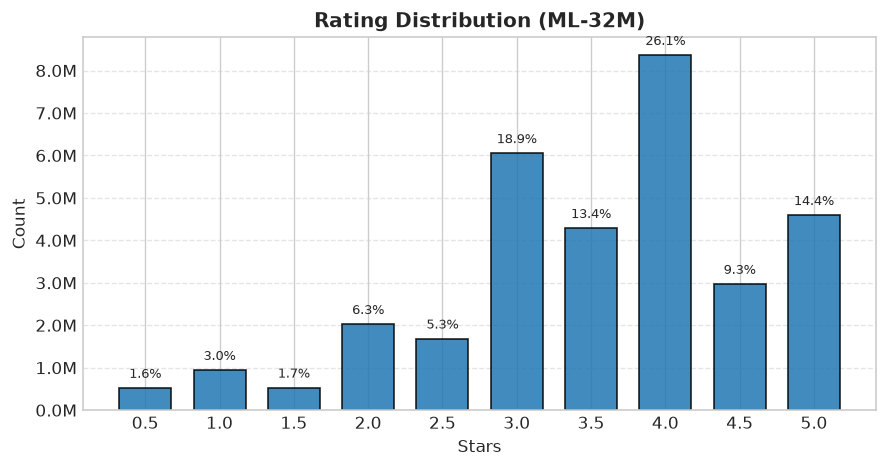

In [4]:
ratings_raw = np.array(dataset["users_ratings"], dtype=np.uint8) / 2.0
unique_ratings, rating_counts = np.unique(ratings_raw, return_counts=True)

plt.figure(figsize=(7.5, 4.0))
bars = plt.bar(unique_ratings, rating_counts, width=0.35, color="#1f77b4", edgecolor="black", alpha=0.85)
plt.title("Rating Distribution (ML-32M)", fontsize=12, fontweight="bold")
plt.xlabel("Stars", fontsize=10)
plt.ylabel("Count", fontsize=10)
plt.xticks(unique_ratings)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x*1e-6:.1f}M'))
plt.grid(axis='y', linestyle='--', alpha=0.5)

total_r = len(ratings_raw)
for bar in bars:
    h = bar.get_height()
    pct = (h / total_r) * 100
    plt.text(bar.get_x() + bar.get_width() / 2, h + total_r * 0.005, f"{pct:.1f}%", ha='center', va='bottom', fontsize=8.0)

plt.tight_layout()
plt.show()

### 1.3 User and Movie Degree Distributions (Log-Log Scale)
We compute the number of ratings per user (out-degree) and per movie (in-degree) from the CSR offset arrays and plot their frequency distributions on a log-log scale.

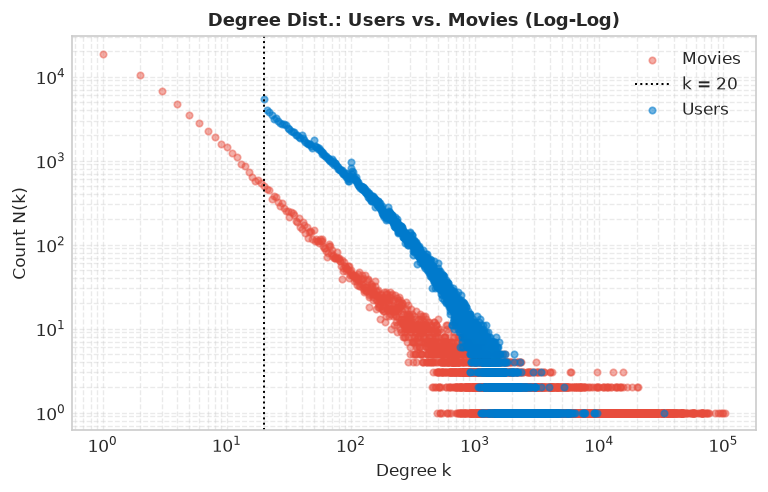

In [5]:
users_offsets = np.array(dataset["users_offsets"], dtype=np.int64)
movies_offsets = np.array(dataset["movies_offsets"], dtype=np.int64)

movies_per_user = np.diff(users_offsets)
users_per_movie = np.diff(movies_offsets)

u_deg, u_counts = np.unique(movies_per_user, return_counts=True)
m_deg, m_counts = np.unique(users_per_movie, return_counts=True)

fig, ax = plt.subplots(figsize=(6.5, 4.2))

ax.scatter(m_deg, m_counts, color="#e74c3c", alpha=0.45, s=15, label="Movies")
ax.axvline(x=20, color="black", linestyle=":", linewidth=1.2, label="k = 20")
ax.scatter(u_deg, u_counts, color="#007acc", alpha=0.55, s=15, label="Users")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Degree Dist.: Users vs. Movies (Log-Log)", fontsize=11, fontweight="bold")
ax.set_xlabel("Degree k")
ax.set_ylabel("Count N(k)")
ax.grid(True, which="both", linestyle="--", alpha=0.4)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

---
# Practical 2: Bias-Only Model (ALS)

### 2.1 Train/Test Split and CSR Indexing
We split the dataset into training ($80\%$) and test ($20\%$) sets and build both user-indexed and movie-indexed CSR views with ratings converted to star units ($0.5..5.0$).

In [6]:
def get_train_test_split(dataset: Dict[str, Any]) -> Tuple[Dict[str, Any], Dict[str, Any]]:
    """Splits the dual-indexed dataset into user-centric and movie-centric train/test CSR views."""
    train_data = {}
    test_data = {}

    n_u = len(dataset["users_offsets"]) - 1
    n_m = len(dataset["movies_offsets"]) - 1

    # Movie-centric view
    m_ratings = np.array(dataset["movies_ratings"], dtype=np.float64) / 2.0
    m_offsets = np.array(dataset["movies_offsets"], dtype=np.int64)
    m_counts_all = np.diff(m_offsets)
    movies_ids = np.repeat(np.arange(n_m, dtype=np.int32), m_counts_all)
    m_mask = np.array(dataset["movies_labels"], dtype=np.uint8) > 0

    train_data["movies_ratings"] = np.ascontiguousarray(m_ratings[m_mask])
    test_data["movies_ratings"] = np.ascontiguousarray(m_ratings[~m_mask])
    train_data["movies_ids"] = np.ascontiguousarray(movies_ids[m_mask])
    test_data["movies_ids"] = np.ascontiguousarray(movies_ids[~m_mask])
    train_data["movies_users"] = np.ascontiguousarray(np.array(dataset["movies_users"], dtype=np.int32)[m_mask])
    test_data["movies_users"] = np.ascontiguousarray(np.array(dataset["movies_users"], dtype=np.int32)[~m_mask])

    train_m_counts = np.bincount(train_data["movies_ids"], minlength=n_m)
    train_data["movies_offsets"] = np.zeros(n_m + 1, dtype=np.int64)
    train_data["movies_offsets"][1:] = np.cumsum(train_m_counts)

    # User-centric view
    u_ratings = np.array(dataset["users_ratings"], dtype=np.float64) / 2.0
    u_offsets = np.array(dataset["users_offsets"], dtype=np.int64)
    u_counts_all = np.diff(u_offsets)
    users_ids = np.repeat(np.arange(n_u, dtype=np.int32), u_counts_all)
    u_mask = np.array(dataset["users_labels"], dtype=np.uint8) > 0

    train_data["users_ratings"] = np.ascontiguousarray(u_ratings[u_mask])
    test_data["users_ratings"] = np.ascontiguousarray(u_ratings[~u_mask])
    train_data["users_ids"] = np.ascontiguousarray(users_ids[u_mask])
    test_data["users_ids"] = np.ascontiguousarray(users_ids[~u_mask])
    train_data["users_movies"] = np.ascontiguousarray(np.array(dataset["users_movies"], dtype=np.int32)[u_mask])
    test_data["users_movies"] = np.ascontiguousarray(np.array(dataset["users_movies"], dtype=np.int32)[~u_mask])

    train_u_counts = np.bincount(train_data["users_ids"], minlength=n_u)
    train_data["users_offsets"] = np.zeros(n_u + 1, dtype=np.int64)
    train_data["users_offsets"][1:] = np.cumsum(train_u_counts)

    return train_data, test_data


t0 = time.perf_counter()
train_data, test_data = get_train_test_split(dataset)
print(f"Split finished in {time.perf_counter() - t0:.2f}s | Train: {len(train_data['users_ratings']):,} | Test: {len(test_data['users_ratings']):,}")

Split finished in 3.20s | Train: 25,604,307 | Test: 6,395,897


### 2.2 Bias-Only ALS Update Functions
We implement the closed-form alternating least squares updates for user biases $a_u$ and movie biases $b_i$, along with the loss and RMSE evaluation functions.

In [7]:
def init_bias_params(n_users: int, n_movies: int) -> Tuple[np.ndarray, np.ndarray]:
    return np.zeros(n_users, dtype=np.float64), np.zeros(n_movies, dtype=np.float64)


def update_entities_bias(own_bias: np.ndarray, other_bias: np.ndarray,
                         ratings: np.ndarray, other_ids: np.ndarray,
                         unique_ids: np.ndarray, inv_idx: np.ndarray, counts: np.ndarray,
                         lambdda: float, gamma: float, mu: float) -> None:
    residues = ratings - other_bias[other_ids] - mu
    summed_residues = np.bincount(inv_idx, weights=residues) * lambdda
    own_bias[unique_ids] = summed_residues / (lambdda * counts + gamma)


def compute_bias_metrics(users_bias: np.ndarray, movies_bias: np.ndarray,
                         mu: float, lambdda: float, gamma: float,
                         dataset_view: Dict[str, Any], by_movie: bool = False) -> Tuple[float, float, float]:
    if not by_movie:
        ratings = dataset_view["users_ratings"]
        u_idx = dataset_view["users_ids"]
        m_idx = dataset_view["users_movies"]
    else:
        ratings = dataset_view["movies_ratings"]
        u_idx = dataset_view["movies_users"]
        m_idx = dataset_view["movies_ids"]

    err = ratings - (mu + users_bias[u_idx] + movies_bias[m_idx])
    sse = float(np.sum(err ** 2))
    nll = 0.5 * lambdda * sse
    reg = 0.5 * gamma * float(np.sum(users_bias ** 2) + np.sum(movies_bias ** 2))
    rmse = float(np.sqrt(sse / len(ratings)))
    return nll, nll + reg, rmse

### 2.3 Training the Bias-Only Model
We run the bias-only ALS algorithm for $10$ iterations and check that the loss computed from `data_by_user_train` and `data_by_movie_train` is identical.

In [8]:
u_ids, u_inv_idx, u_counts = np.unique(train_data["users_ids"], return_inverse=True, return_counts=True)
m_ids, m_inv_idx, m_counts = np.unique(train_data["movies_ids"], return_inverse=True, return_counts=True)

lambdda_b = 1.0
gamma_b = 5.0
mu = float(np.mean(train_data["users_ratings"]))
n_iters_b = 10

users_bias_p2, movies_bias_p2 = init_bias_params(n_users, n_movies)

p2_nll_user, p2_loss_user, p2_tr_rmse, p2_te_rmse = [], [], [], []
p2_loss_movie = []

nll_u, loss_u, tr_r = compute_bias_metrics(users_bias_p2, movies_bias_p2, mu, lambdda_b, gamma_b, train_data, by_movie=False)
_, loss_m, _ = compute_bias_metrics(users_bias_p2, movies_bias_p2, mu, lambdda_b, gamma_b, train_data, by_movie=True)
_, _, te_r = compute_bias_metrics(users_bias_p2, movies_bias_p2, mu, lambdda_b, gamma_b, test_data, by_movie=False)

p2_nll_user.append(nll_u)
p2_loss_user.append(loss_u)
p2_loss_movie.append(loss_m)
p2_tr_rmse.append(tr_r)
p2_te_rmse.append(te_r)

print(f"Iter  0 | Loss (User): {loss_u:13,.2f} | Loss (Movie): {loss_m:13,.2f} | Train RMSE: {tr_r:.4f} | Test RMSE: {te_r:.4f}")
t0 = time.perf_counter()
for it in range(1, n_iters_b + 1):
    update_entities_bias(users_bias_p2, movies_bias_p2,
                         train_data["users_ratings"], train_data["users_movies"],
                         u_ids, u_inv_idx, u_counts, lambdda_b, gamma_b, mu)
    update_entities_bias(movies_bias_p2, users_bias_p2,
                         train_data["movies_ratings"], train_data["movies_users"],
                         m_ids, m_inv_idx, m_counts, lambdda_b, gamma_b, mu)

    nll_u, loss_u, tr_r = compute_bias_metrics(users_bias_p2, movies_bias_p2, mu, lambdda_b, gamma_b, train_data, by_movie=False)
    _, loss_m, _ = compute_bias_metrics(users_bias_p2, movies_bias_p2, mu, lambdda_b, gamma_b, train_data, by_movie=True)
    _, _, te_r = compute_bias_metrics(users_bias_p2, movies_bias_p2, mu, lambdda_b, gamma_b, test_data, by_movie=False)

    p2_nll_user.append(nll_u)
    p2_loss_user.append(loss_u)
    p2_loss_movie.append(loss_m)
    p2_tr_rmse.append(tr_r)
    p2_te_rmse.append(te_r)
    print(f"Iter {it:2d} | Loss (User): {loss_u:13,.2f} | Loss (Movie): {loss_m:13,.2f} | Train RMSE: {tr_r:.4f} | Test RMSE: {te_r:.4f}")

print(f"Completed in {time.perf_counter() - t0:.2f}s | Max |Loss_user - Loss_movie| = { max(abs(a - b) for a, b in zip(p2_loss_user, p2_loss_movie)):.2e}")

Iter  0 | Loss (User): 14,354,702.85 | Loss (Movie): 14,354,702.85 | Train RMSE: 1.0589 | Test RMSE: 1.0593
Iter  1 | Loss (User):  9,619,726.85 | Loss (Movie):  9,619,726.85 | Train RMSE: 0.8611 | Test RMSE: 0.8698
Iter  2 | Loss (User):  9,313,317.90 | Loss (Movie):  9,313,317.90 | Train RMSE: 0.8477 | Test RMSE: 0.8564
Iter  3 | Loss (User):  9,299,242.94 | Loss (Movie):  9,299,242.94 | Train RMSE: 0.8471 | Test RMSE: 0.8557
Iter  4 | Loss (User):  9,297,698.73 | Loss (Movie):  9,297,698.73 | Train RMSE: 0.8470 | Test RMSE: 0.8557
Iter  5 | Loss (User):  9,296,940.31 | Loss (Movie):  9,296,940.31 | Train RMSE: 0.8470 | Test RMSE: 0.8556
Iter  6 | Loss (User):  9,296,308.16 | Loss (Movie):  9,296,308.16 | Train RMSE: 0.8470 | Test RMSE: 0.8556
Iter  7 | Loss (User):  9,295,738.95 | Loss (Movie):  9,295,738.95 | Train RMSE: 0.8470 | Test RMSE: 0.8556
Iter  8 | Loss (User):  9,295,219.64 | Loss (Movie):  9,295,219.64 | Train RMSE: 0.8470 | Test RMSE: 0.8556
Iter  9 | Loss (User):  9,29

### 2.4 Plotting Bias-Only Loss and RMSE Curves
We plot the regularized loss (by user and by movie) and the training and test RMSE across ALS iterations.

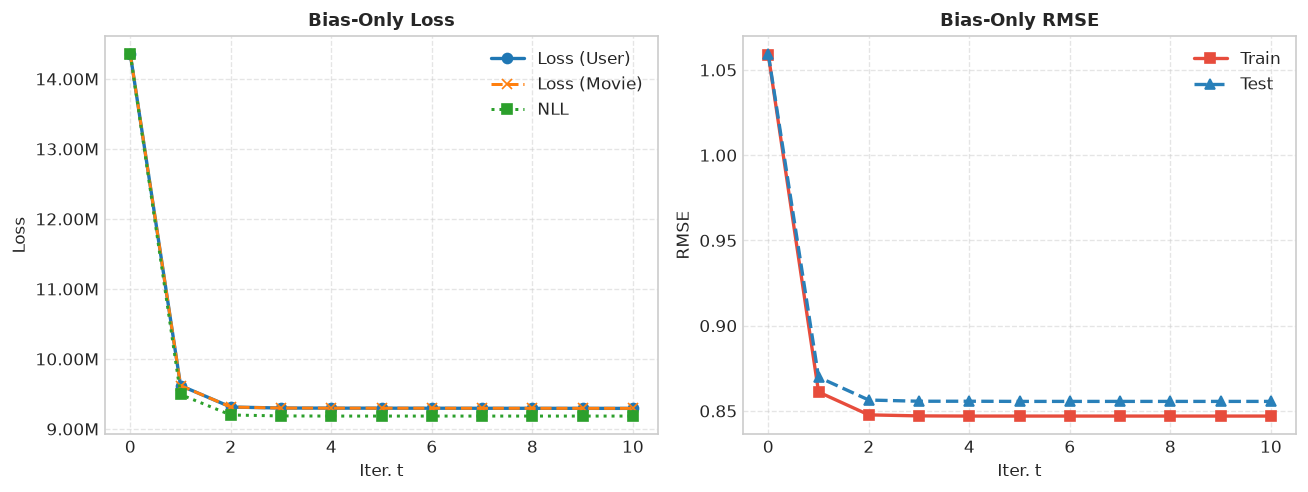

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
iters_b = np.arange(len(p2_loss_user))

axes[0].plot(iters_b, p2_loss_user, marker='o', linewidth=2, color="#1f77b4", label="Loss (User)")
axes[0].plot(iters_b, p2_loss_movie, marker='x', linestyle="--", linewidth=1.8, color="#ff7f0e", label="Loss (Movie)")
axes[0].plot(iters_b, p2_nll_user, marker='s', linestyle=":", linewidth=1.8, color="#2ca02c", label="NLL")
axes[0].set_title("Bias-Only Loss", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Iter. t")
axes[0].set_ylabel("Loss")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x*1e-6:.2f}M'))
axes[0].legend(frameon=False)
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(iters_b, p2_tr_rmse, marker='s', linewidth=2, color="#e74c3c", label="Train")
axes[1].plot(iters_b, p2_te_rmse, marker='^', linestyle="--", linewidth=2, color="#2980b9", label="Test")
axes[1].set_title("Bias-Only RMSE", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Iter. t")
axes[1].set_ylabel("RMSE")
axes[1].legend(frameon=False)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

---
# Practical 3: Matrix Factorization Model (ALS)

### 3.1 Batched NumPy Matrix Factorization Implementation
We implement the matrix factorization ALS updates for user biases $a_u$, user trait vectors $u_u \in \mathbb{R}^K$, movie biases $b_i$, and movie trait vectors $v_i \in \mathbb{R}^K$ using chunked NumPy `reduceat` outer-product accumulation and `np.linalg.solve`.

In [10]:
def init_pmf_params(n_users: int, n_movies: int, emb_dim: int = 10,
                    tau: float = 5.0, seed: int = 42) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    rng = np.random.default_rng(seed)
    scale = 1.0 / np.sqrt(emb_dim * max(tau, 1.0))
    users_bias = np.zeros(n_users, dtype=np.float64)
    movies_bias = np.zeros(n_movies, dtype=np.float64)
    users_emb = rng.normal(0.0, scale, size=(n_users, emb_dim)).astype(np.float64)
    movies_emb = rng.normal(0.0, scale, size=(n_movies, emb_dim)).astype(np.float64)
    return users_emb, users_bias, movies_emb, movies_bias


def get_breakpoints(offsets: np.ndarray, chunk_size: int = 800_000) -> List[int]:
    breakpoints = [0]
    counts = np.diff(offsets)
    size = 0
    for i, count in enumerate(counts):
        if size + count > chunk_size and size > 0:
            breakpoints.append(int(offsets[i]))
            size = 0
        size += int(count)
    breakpoints.append(int(offsets[-1]))
    return breakpoints


def update_entities(own_bias: np.ndarray, own_emb: np.ndarray,
                    other_bias: np.ndarray, other_emb: np.ndarray,
                    ratings: np.ndarray, own_ids: np.ndarray, other_ids: np.ndarray,
                    unique_ids: np.ndarray, inv_idx: np.ndarray, counts: np.ndarray,
                    breakpoints: List[int], mu: float, lambdda: float,
                    gamma: float, tau: float, chunk_size: int = 2_000_000) -> None:
    # 1. Update biases
    n = len(ratings)
    residues = np.empty(n, dtype=np.float64)
    for start in range(0, n, chunk_size):
        end = min(start + chunk_size, n)
        dots = np.sum(own_emb[own_ids[start:end]] * other_emb[other_ids[start:end]], axis=1)
        residues[start:end] = ratings[start:end] - other_bias[other_ids[start:end]] - mu - dots
    summed = np.bincount(inv_idx, weights=residues) * lambdda
    own_bias[unique_ids] = summed / (lambdda * counts + gamma)

    # 2. Update embeddings (chunked NumPy reduceat + linalg.solve)
    k = own_emb.shape[1]
    eye_k = tau * np.eye(k, dtype=np.float64)[None, :, :]

    for i in range(len(breakpoints) - 1):
        start, end = breakpoints[i], breakpoints[i + 1]
        if start >= end:
            continue
        e_slice = own_ids[start:end]
        o_slice = other_ids[start:end]
        mask = e_slice[:-1] != e_slice[1:]
        cut_points = np.concatenate(([0], np.nonzero(mask)[0] + 1))
        chunk_ids = e_slice[cut_points]

        res = (ratings[start:end] - other_bias[o_slice] - own_bias[e_slice] - mu) * lambdda
        vo = other_emb[o_slice]
        y_accum = np.add.reduceat(res[:, None] * vo, cut_points, axis=0)

        A_inter = (vo[:, :, None] * vo[:, None, :]) * lambdda
        A_accum = np.add.reduceat(A_inter, cut_points, axis=0) + eye_k
        own_emb[chunk_ids] = np.linalg.solve(A_accum, y_accum[:, :, None]).squeeze(-1)


def compute_pmf_metrics(users_emb: np.ndarray, users_bias: np.ndarray,
                        movies_emb: np.ndarray, movies_bias: np.ndarray,
                        mu: float, lambdda: float, gamma: float, tau: float,
                        dataset_view: Dict[str, Any], chunk_size: int = 2_000_000) -> Tuple[float, float, float]:
    ratings = dataset_view["users_ratings"]
    u_idx = dataset_view["users_ids"]
    m_idx = dataset_view["users_movies"]
    n = len(ratings)
    sse = 0.0
    for start in range(0, n, chunk_size):
        end = min(start + chunk_size, n)
        dots = np.sum(users_emb[u_idx[start:end]] * movies_emb[m_idx[start:end]], axis=1)
        preds = mu + users_bias[u_idx[start:end]] + movies_bias[m_idx[start:end]] + dots
        sse += float(np.sum((ratings[start:end] - preds) ** 2))

    nll = 0.5 * lambdda * sse
    reg_b = 0.5 * gamma * float(np.sum(users_bias ** 2) + np.sum(movies_bias ** 2))
    reg_f = 0.5 * tau * float(np.sum(users_emb ** 2) + np.sum(movies_emb ** 2))
    rmse = float(np.sqrt(sse / n))
    return nll, nll + reg_b + reg_f, rmse

### 3.2 Training the Batched NumPy Matrix Factorization Model
We run the batched NumPy ALS algorithm with $K = 5$ latent factors ($\lambda = 1.0, \gamma = 0.1, \tau = 5.0$) for $6$ iterations.

In [11]:
emb_dim_p3 = 5
lambdda_p3 = 1.0
gamma_p3 = 0.1
tau_p3 = 5.0
n_iters_p3 = 6

users_emb_p3, users_bias_p3, movies_emb_p3, movies_bias_p3 = init_pmf_params(
    n_users, n_movies, emb_dim=emb_dim_p3, tau=tau_p3
)

u_breakpoints = get_breakpoints(train_data["users_offsets"], chunk_size=800_000)
m_breakpoints = get_breakpoints(train_data["movies_offsets"], chunk_size=800_000)

p3_nll_hist, p3_loss_hist, p3_tr_rmse, p3_te_rmse = [], [], [], []

nll0, loss0, tr0 = compute_pmf_metrics(users_emb_p3, users_bias_p3, movies_emb_p3, movies_bias_p3, mu, lambdda_p3, gamma_p3, tau_p3, train_data)
_, _, te0 = compute_pmf_metrics(users_emb_p3, users_bias_p3, movies_emb_p3, movies_bias_p3, mu, lambdda_p3, gamma_p3, tau_p3, test_data)
p3_nll_hist.append(nll0)
p3_loss_hist.append(loss0)
p3_tr_rmse.append(tr0)
p3_te_rmse.append(te0)
print(f"Iter  0 | NLL: {nll0:13,.2f} | Total Loss: {loss0:13,.2f} | Train RMSE: {tr0:.4f} | Test RMSE: {te0:.4f}")

t_p3 = time.perf_counter()
for it in range(1, n_iters_p3 + 1):
    t_ep = time.perf_counter()
    update_entities(users_bias_p3, users_emb_p3, movies_bias_p3, movies_emb_p3,
                    train_data["users_ratings"], train_data["users_ids"], train_data["users_movies"],
                    u_ids, u_inv_idx, u_counts, u_breakpoints, mu, lambdda_p3, gamma_p3, tau_p3)
    update_entities(movies_bias_p3, movies_emb_p3, users_bias_p3, users_emb_p3,
                    train_data["movies_ratings"], train_data["movies_ids"], train_data["movies_users"],
                    m_ids, m_inv_idx, m_counts, m_breakpoints, mu, lambdda_p3, gamma_p3, tau_p3)

    nll, loss, tr_r = compute_pmf_metrics(users_emb_p3, users_bias_p3, movies_emb_p3, movies_bias_p3, mu, lambdda_p3, gamma_p3, tau_p3, train_data)
    _, _, te_r = compute_pmf_metrics(users_emb_p3, users_bias_p3, movies_emb_p3, movies_bias_p3, mu, lambdda_p3, gamma_p3, tau_p3, test_data)

    p3_nll_hist.append(nll)
    p3_loss_hist.append(loss)
    p3_tr_rmse.append(tr_r)
    p3_te_rmse.append(te_r)
    print(f"Iter {it:2d} | NLL: {nll:13,.2f} | Total Loss: {loss:13,.2f} | Train RMSE: {tr_r:.4f} | Test RMSE: {te_r:.4f} ({time.perf_counter() - t_ep:.2f}s)")

print(f"Batched NumPy PMF completed in {time.perf_counter() - t_p3:.2f}s.")

Iter  0 | NLL: 14,455,883.03 | Total Loss: 14,598,539.16 | Train RMSE: 1.0626 | Test RMSE: 1.0631
Iter  1 | NLL:  9,141,129.88 | Total Loss:  9,250,082.90 | Train RMSE: 0.8450 | Test RMSE: 0.8791 (26.61s)
Iter  2 | NLL:  8,152,393.07 | Total Loss:  8,319,223.02 | Train RMSE: 0.7980 | Test RMSE: 0.8396 (25.79s)
Iter  3 | NLL:  7,697,952.46 | Total Loss:  7,895,543.20 | Train RMSE: 0.7754 | Test RMSE: 0.8184 (25.43s)
Iter  4 | NLL:  7,494,724.32 | Total Loss:  7,705,087.74 | Train RMSE: 0.7651 | Test RMSE: 0.8087 (25.17s)
Iter  5 | NLL:  7,377,272.54 | Total Loss:  7,593,406.38 | Train RMSE: 0.7591 | Test RMSE: 0.8030 (25.19s)
Iter  6 | NLL:  7,299,201.79 | Total Loss:  7,518,087.65 | Train RMSE: 0.7551 | Test RMSE: 0.7992 (25.38s)
Batched NumPy PMF completed in 153.57s.


### 3.3 Plotting Matrix Factorization Loss and RMSE Curves
We plot the NLL and Total Regularized Loss, the Train and Test RMSE curves, and the comparison with the Bias-Only model.

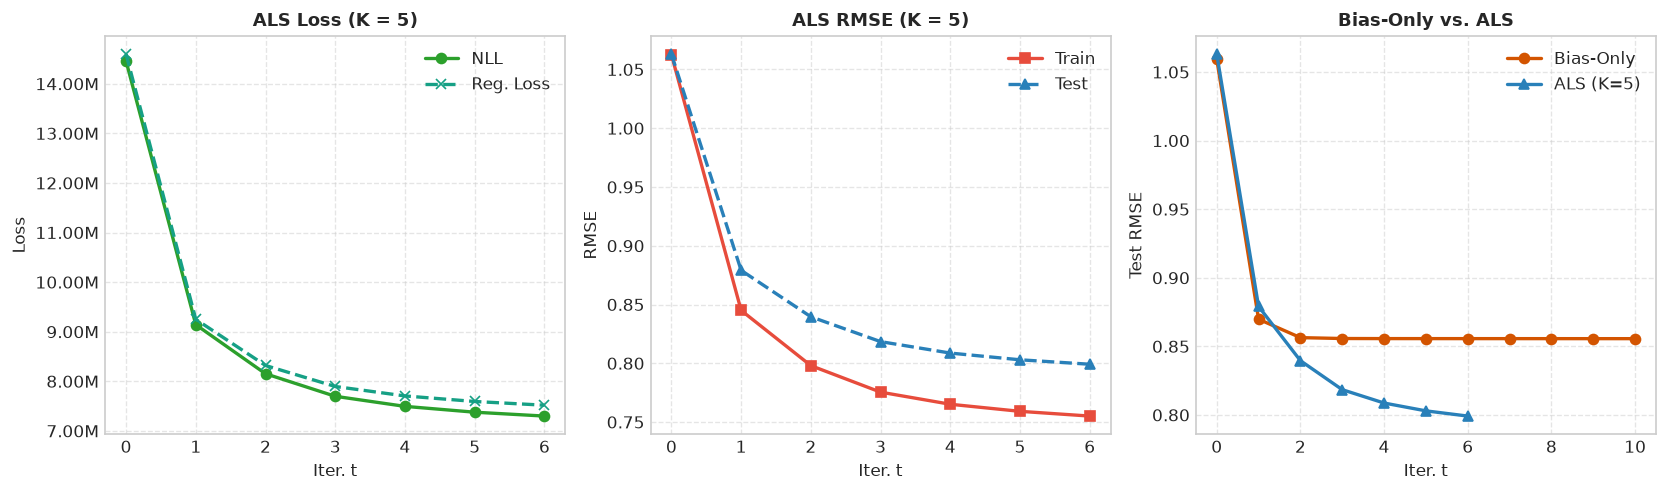

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
iters_p3 = np.arange(len(p3_loss_hist))

axes[0].plot(iters_p3, p3_nll_hist, marker='o', linewidth=2, color="#2ca02c", label="NLL")
axes[0].plot(iters_p3, p3_loss_hist, marker='x', linestyle="--", linewidth=2, color="#16a085", label="Reg. Loss")
axes[0].set_title(f"ALS Loss (K = {emb_dim_p3})", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Iter. t")
axes[0].set_ylabel("Loss")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x*1e-6:.2f}M'))
axes[0].legend(frameon=False)
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(iters_p3, p3_tr_rmse, marker='s', linewidth=2, color="#e74c3c", label="Train")
axes[1].plot(iters_p3, p3_te_rmse, marker='^', linestyle="--", linewidth=2, color="#2980b9", label="Test")
axes[1].set_title(f"ALS RMSE (K = {emb_dim_p3})", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Iter. t")
axes[1].set_ylabel("RMSE")
axes[1].legend(frameon=False)
axes[1].grid(True, linestyle="--", alpha=0.5)

axes[2].plot(np.arange(len(p2_te_rmse)), p2_te_rmse, marker='o', linewidth=2, color="#d35400", label="Bias-Only")
axes[2].plot(iters_p3, p3_te_rmse, marker='^', linewidth=2, color="#2980b9", label=f"ALS (K={emb_dim_p3})")
axes[2].set_title("Bias-Only vs. ALS", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Iter. t")
axes[2].set_ylabel("Test RMSE")
axes[2].legend(frameon=False)
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

---
# Practical 4: Accelerated ALS, Movie Embeddings, and Recommendations

### 4.1 Accelerated Matrix Factorization (Numba Parallel CSR + In-Place Cholesky)
We accelerate the ALS updates using Numba `@njit(parallel=True, fastmath=True)` over the CSR offsets, accumulating only the lower triangle of each $K \times K$ normal matrix and solving in-place via Cholesky factorization.

In [13]:
@njit(fastmath=True)
def _cholesky_solve_inplace(A: np.ndarray, b: np.ndarray, out: np.ndarray) -> None:
    k = A.shape[0]
    for i in range(k):
        for j in range(i + 1):
            s = A[i, j]
            for p in range(j):
                s -= A[i, p] * A[j, p]
            if i == j:
                if s <= 1e-12:
                    s = 1e-12
                A[i, i] = np.sqrt(s)
            else:
                A[i, j] = s / A[j, j]

    for i in range(k):
        s = b[i]
        for p in range(i):
            s -= A[i, p] * out[p]
        out[i] = s / A[i, i]

    for i in range(k - 1, -1, -1):
        s = out[i]
        for p in range(i + 1, k):
            s -= A[p, i] * out[p]
        out[i] = s / A[i, i]


@njit(parallel=True, fastmath=True)
def update_entities_numba(own_bias: np.ndarray, own_emb: np.ndarray,
                          other_bias: np.ndarray, other_emb: np.ndarray,
                          offsets: np.ndarray, other_ids: np.ndarray, ratings: np.ndarray,
                          mu: float, lambdda: float, gamma: float, tau: float) -> None:
    n_entities = len(offsets) - 1
    k = own_emb.shape[1]

    for e in prange(n_entities):
        start = offsets[e]
        end = offsets[e + 1]
        count = end - start
        if count == 0:
            own_bias[e] = 0.0
            for d in range(k):
                own_emb[e, d] = 0.0
            continue

        # 1. Update bias
        sum_res = 0.0
        for idx in range(start, end):
            o = other_ids[idx]
            dot = 0.0
            for d in range(k):
                dot += own_emb[e, d] * other_emb[o, d]
            sum_res += ratings[idx] - mu - other_bias[o] - dot
        be = (lambdda * sum_res) / (lambdda * count + gamma)
        own_bias[e] = be

        # 2. Accumulate lower triangle of A and RHS b
        A = np.zeros((k, k), dtype=np.float64)
        b = np.zeros(k, dtype=np.float64)
        for d in range(k):
            A[d, d] = tau

        for idx in range(start, end):
            o = other_ids[idx]
            r_res = lambdda * (ratings[idx] - mu - be - other_bias[o])
            for d1 in range(k):
                vo1 = other_emb[o, d1]
                b[d1] += r_res * vo1
                l_vo1 = lambdda * vo1
                for d2 in range(d1 + 1):
                    A[d1, d2] += l_vo1 * other_emb[o, d2]

        _cholesky_solve_inplace(A, b, own_emb[e])


@njit(parallel=True, fastmath=True)
def compute_metrics_numba(users_bias: np.ndarray, users_emb: np.ndarray,
                          movies_bias: np.ndarray, movies_emb: np.ndarray,
                          u_offsets: np.ndarray, u_movies: np.ndarray, u_ratings: np.ndarray,
                          mu: float, lambdda: float, gamma: float, tau: float) -> Tuple[float, float, float]:
    n_users = len(u_offsets) - 1
    k = users_emb.shape[1]
    sse = 0.0
    for u in prange(n_users):
        start = u_offsets[u]
        end = u_offsets[u + 1]
        bu = users_bias[u]
        u_sse = 0.0
        for idx in range(start, end):
            m = u_movies[idx]
            dot = 0.0
            for d in range(k):
                dot += users_emb[u, d] * movies_emb[m, d]
            err = u_ratings[idx] - (mu + bu + movies_bias[m] + dot)
            u_sse += err * err
        sse += u_sse

    nll = 0.5 * lambdda * sse
    reg_b = 0.5 * gamma * (np.sum(users_bias ** 2) + np.sum(movies_bias ** 2))
    reg_f = 0.5 * tau * (np.sum(users_emb ** 2) + np.sum(movies_emb ** 2))
    rmse = np.sqrt(sse / len(u_ratings))
    return nll, nll + reg_b + reg_f, rmse


@njit(parallel=True, fastmath=True)
def compute_test_rmse_numba(users_bias: np.ndarray, users_emb: np.ndarray,
                            movies_bias: np.ndarray, movies_emb: np.ndarray,
                            u_ids: np.ndarray, m_ids: np.ndarray, ratings: np.ndarray,
                            mu: float) -> float:
    n = len(ratings)
    k = users_emb.shape[1]
    sse = 0.0
    for idx in prange(n):
        u = u_ids[idx]
        m = m_ids[idx]
        dot = 0.0
        for d in range(k):
            dot += users_emb[u, d] * movies_emb[m, d]
        err = ratings[idx] - (mu + users_bias[u] + movies_bias[m] + dot)
        sse += err * err
    return np.sqrt(sse / n)

We train the accelerated Numba Cholesky ALS model with $K = 16$ ($\lambda = 1.0, \gamma = 0.1, \tau = 5.0$) for $12$ iterations and plot the loss, RMSE, and runtime speedup curves.

In [14]:
emb_dim_p4 = 16
lambdda_p4 = 1.0
gamma_p4 = 0.1
tau_p4 = 5.0
n_iters_p4 = 12

users_emb_p4, users_bias_p4, movies_emb_p4, movies_bias_p4 = init_pmf_params(
    n_users, n_movies, emb_dim=emb_dim_p4, tau=tau_p4
)

# Warm-up JIT compilation
update_entities_numba(users_bias_p4, users_emb_p4, movies_bias_p4, movies_emb_p4,
                      train_data["users_offsets"][:10], train_data["users_movies"], train_data["users_ratings"],
                      mu, lambdda_p4, gamma_p4, tau_p4)

users_emb_p4, users_bias_p4, movies_emb_p4, movies_bias_p4 = init_pmf_params(
    n_users, n_movies, emb_dim=emb_dim_p4, tau=tau_p4
)

p4_nll_hist, p4_loss_hist, p4_tr_rmse, p4_te_rmse = [], [], [], []
nll0, loss0, tr0 = compute_metrics_numba(users_bias_p4, users_emb_p4, movies_bias_p4, movies_emb_p4,
                                         train_data["users_offsets"], train_data["users_movies"], train_data["users_ratings"],
                                         mu, lambdda_p4, gamma_p4, tau_p4)
te0 = compute_test_rmse_numba(users_bias_p4, users_emb_p4, movies_bias_p4, movies_emb_p4,
                              test_data["users_ids"], test_data["users_movies"], test_data["users_ratings"], mu)
p4_nll_hist.append(nll0)
p4_loss_hist.append(loss0)
p4_tr_rmse.append(tr0)
p4_te_rmse.append(te0)
print(f"Iter  0 | NLL: {nll0:13,.2f} | Total Loss: {loss0:13,.2f} | Train RMSE: {tr0:.4f} | Test RMSE: {te0:.4f}")

t_p4 = time.perf_counter()
for it in range(1, n_iters_p4 + 1):
    t_ep = time.perf_counter()
    update_entities_numba(users_bias_p4, users_emb_p4, movies_bias_p4, movies_emb_p4,
                          train_data["users_offsets"], train_data["users_movies"], train_data["users_ratings"],
                          mu, lambdda_p4, gamma_p4, tau_p4)
    update_entities_numba(movies_bias_p4, movies_emb_p4, users_bias_p4, users_emb_p4,
                          train_data["movies_offsets"], train_data["movies_users"], train_data["movies_ratings"],
                          mu, lambdda_p4, gamma_p4, tau_p4)
    ep_sec = time.perf_counter() - t_ep

    nll, loss, tr_r = compute_metrics_numba(users_bias_p4, users_emb_p4, movies_bias_p4, movies_emb_p4,
                                            train_data["users_offsets"], train_data["users_movies"], train_data["users_ratings"],
                                            mu, lambdda_p4, gamma_p4, tau_p4)
    te_r = compute_test_rmse_numba(users_bias_p4, users_emb_p4, movies_bias_p4, movies_emb_p4,
                                  test_data["users_ids"], test_data["users_movies"], test_data["users_ratings"], mu)

    p4_nll_hist.append(nll)
    p4_loss_hist.append(loss)
    p4_tr_rmse.append(tr_r)
    p4_te_rmse.append(te_r)
    print(f"Iter {it:2d} | NLL: {nll:13,.2f} | Total Loss: {loss:13,.2f} | Train RMSE: {tr_r:.4f} | Test RMSE: {te_r:.4f} ({ep_sec:.2f}s)")

print(f"Accelerated Numba Cholesky ALS finished in {time.perf_counter() - t_p4:.2f}s.")

Iter  0 | NLL: 14,387,257.46 | Total Loss: 14,529,843.66 | Train RMSE: 1.0601 | Test RMSE: 1.0605
Iter  1 | NLL:  8,542,716.09 | Total Loss:  8,774,126.77 | Train RMSE: 0.8169 | Test RMSE: 0.8843 (2.80s)
Iter  2 | NLL:  6,911,662.19 | Total Loss:  7,319,912.33 | Train RMSE: 0.7348 | Test RMSE: 0.8314 (2.99s)
Iter  3 | NLL:  6,371,794.31 | Total Loss:  6,803,548.42 | Train RMSE: 0.7055 | Test RMSE: 0.8068 (2.83s)
Iter  4 | NLL:  6,132,957.06 | Total Loss:  6,566,293.13 | Train RMSE: 0.6921 | Test RMSE: 0.7954 (2.82s)
Iter  5 | NLL:  6,010,305.36 | Total Loss:  6,439,755.86 | Train RMSE: 0.6852 | Test RMSE: 0.7899 (2.83s)
Iter  6 | NLL:  5,939,665.27 | Total Loss:  6,363,976.07 | Train RMSE: 0.6811 | Test RMSE: 0.7870 (2.88s)
Iter  7 | NLL:  5,894,597.25 | Total Loss:  6,313,972.60 | Train RMSE: 0.6786 | Test RMSE: 0.7853 (2.81s)
Iter  8 | NLL:  5,863,267.45 | Total Loss:  6,278,331.24 | Train RMSE: 0.6768 | Test RMSE: 0.7843 (2.80s)
Iter  9 | NLL:  5,840,082.61 | Total Loss:  6,251,499.

We plot the convergence curves of the accelerated model and the runtime speedup across latent dimensions $K$.

K =  2 | NumPy:   7.75s | Numba Cholesky:  0.36s | Speedup:  21.7x
K =  4 | NumPy:  20.69s | Numba Cholesky:  1.08s | Speedup:  19.2x
K =  8 | NumPy:  84.52s | Numba Cholesky:  2.55s | Speedup:  33.2x
K = 12 | NumPy: 176.09s | Numba Cholesky:  3.24s | Speedup:  54.4x
K = 16 | NumPy: 288.44s | Numba Cholesky:  4.18s | Speedup:  69.1x


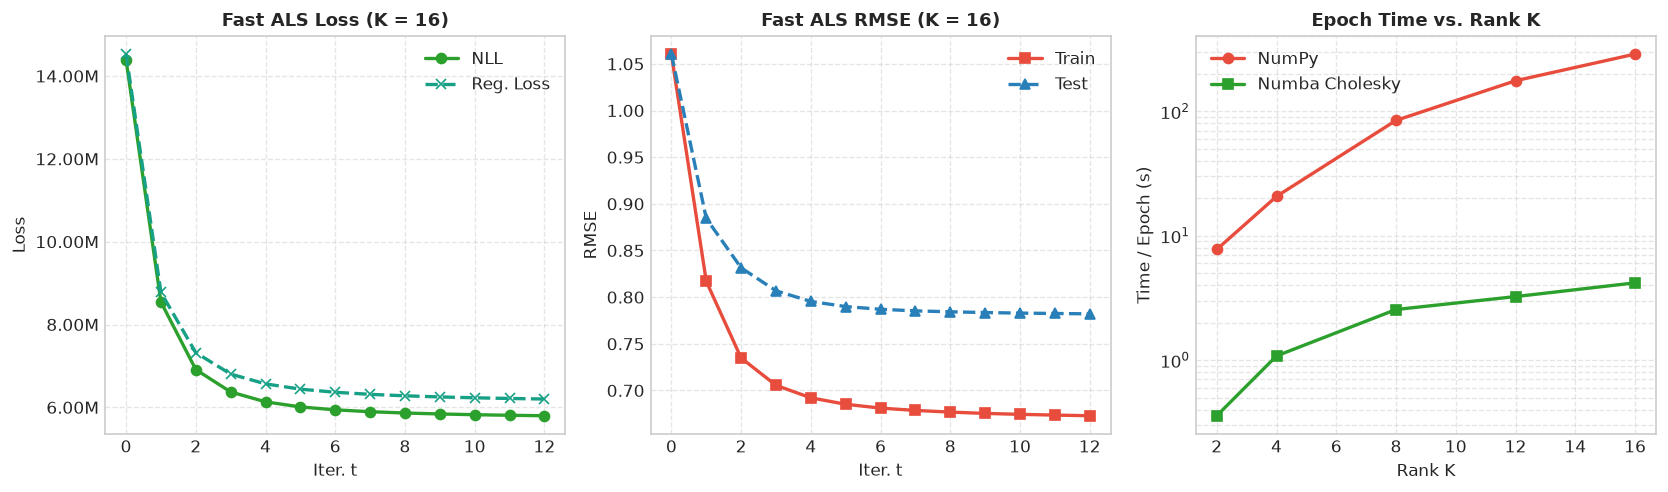

In [15]:
# Measure epoch runtime across K for Batched NumPy vs Accelerated Numba Cholesky
k_bench = [2, 4, 8, 12, 16]
numpy_sec = []
numba_sec = []

u_bp_bench = get_breakpoints(train_data["users_offsets"], chunk_size=250_000)
m_bp_bench = get_breakpoints(train_data["movies_offsets"], chunk_size=250_000)

for k_val in k_bench:
    u_e, u_b, m_e, m_b = init_pmf_params(n_users, n_movies, emb_dim=k_val, tau=tau_p4)

    # Time 1 full epoch of Batched NumPy ALS
    t0_np = time.perf_counter()
    update_entities(u_b, u_e, m_b, m_e,
                    train_data["users_ratings"], train_data["users_ids"], train_data["users_movies"],
                    u_ids, u_inv_idx, u_counts, u_bp_bench, mu, lambdda_p4, gamma_p4, tau_p4)
    update_entities(m_b, m_e, u_b, u_e,
                    train_data["movies_ratings"], train_data["movies_ids"], train_data["movies_users"],
                    m_ids, m_inv_idx, m_counts, m_bp_bench, mu, lambdda_p4, gamma_p4, tau_p4)
    dt_np = time.perf_counter() - t0_np
    numpy_sec.append(dt_np)

    # Time 1 full epoch of Accelerated Numba Cholesky ALS
    t0_nb = time.perf_counter()
    update_entities_numba(u_b, u_e, m_b, m_e,
                          train_data["users_offsets"], train_data["users_movies"], train_data["users_ratings"],
                          mu, lambdda_p4, gamma_p4, tau_p4)
    update_entities_numba(m_b, m_e, u_b, u_e,
                          train_data["movies_offsets"], train_data["movies_users"], train_data["movies_ratings"],
                          mu, lambdda_p4, gamma_p4, tau_p4)
    dt_nb = time.perf_counter() - t0_nb
    numba_sec.append(dt_nb)
    print(f"K = {k_val:2d} | NumPy: {dt_np:6.2f}s | Numba Cholesky: {dt_nb:5.2f}s | Speedup: {dt_np / dt_nb:5.1f}x")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
iters_p4 = np.arange(len(p4_loss_hist))

axes[0].plot(iters_p4, p4_nll_hist, marker='o', linewidth=2, color="#2ca02c", label="NLL")
axes[0].plot(iters_p4, p4_loss_hist, marker='x', linestyle="--", linewidth=2, color="#16a085", label="Reg. Loss")
axes[0].set_title(f"Fast ALS Loss (K = {emb_dim_p4})", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Iter. t")
axes[0].set_ylabel("Loss")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x*1e-6:.2f}M'))
axes[0].legend(frameon=False)
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(iters_p4, p4_tr_rmse, marker='s', linewidth=2, color="#e74c3c", label="Train")
axes[1].plot(iters_p4, p4_te_rmse, marker='^', linestyle="--", linewidth=2, color="#2980b9", label="Test")
axes[1].set_title(f"Fast ALS RMSE (K = {emb_dim_p4})", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Iter. t")
axes[1].set_ylabel("RMSE")
axes[1].legend(frameon=False)
axes[1].grid(True, linestyle="--", alpha=0.5)

axes[2].plot(k_bench, numpy_sec, marker='o', linewidth=2, color="#e74c3c", label="NumPy")
axes[2].plot(k_bench, numba_sec, marker='s', linewidth=2, color="#2ca02c", label="Numba Cholesky")
axes[2].set_yscale("log")
axes[2].set_title("Epoch Time vs. Rank K", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Rank K")
axes[2].set_ylabel("Time / Epoch (s)")
axes[2].legend(frameon=False)
axes[2].grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 4.2 2D Movie Embeddings ($K = 2$)
We parse `movies.csv`, train the model with $K = 2$ latent dimensions, and plot the 2D movie embeddings $v_n \in \mathbb{R}^2$.

2D Movie Embedding Model (K=2) Test RMSE: 0.8176


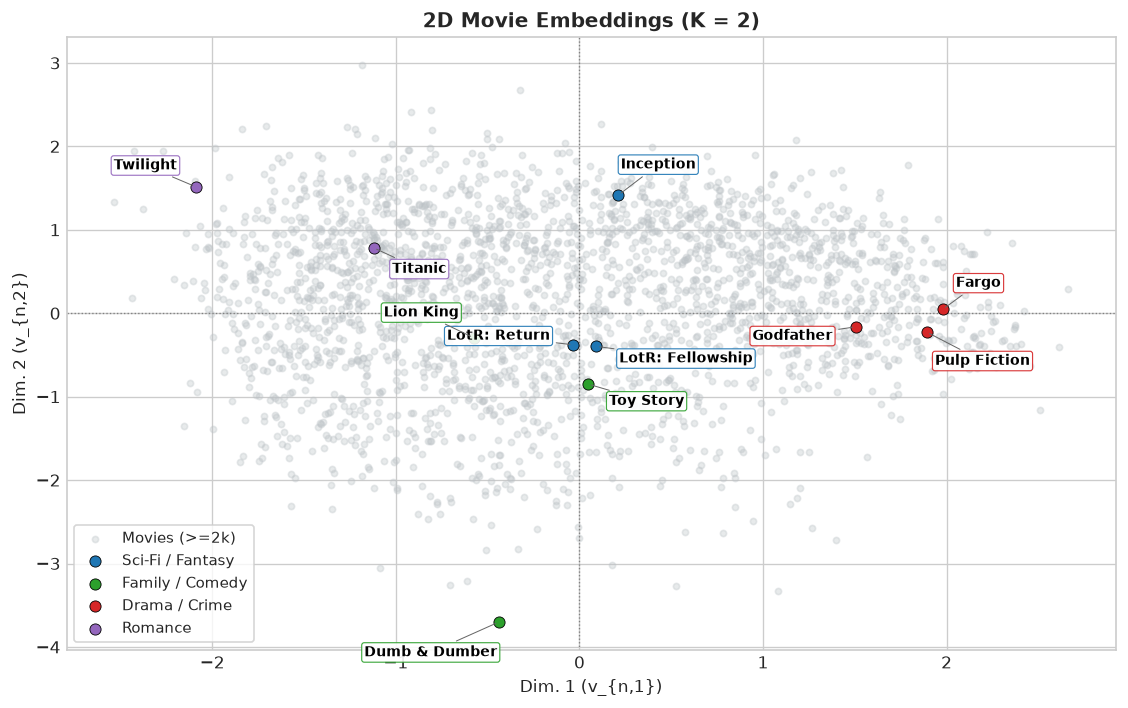

In [16]:
# Parse movie titles and genres from movies.csv
movie_titles = ["Unknown"] * n_movies
movie_genres = ["(no genres listed)"] * n_movies
movies_index = dataset["movies_index"]

with open(MOVIES_CSV_PATH, "r", encoding="utf-8") as f:
    reader = csv.reader(f)
    next(reader, None)
    for row in reader:
        if len(row) < 3:
            continue
        m_idx = movies_index.get(row[0])
        if m_idx is not None:
            movie_titles[m_idx] = row[1]
            movie_genres[m_idx] = row[2]

# Train K=2 model for 2D visualization
users_emb_2d, users_bias_2d, movies_emb_2d, movies_bias_2d = init_pmf_params(n_users, n_movies, emb_dim=2, tau=5.0)
for _ in range(15):
    update_entities_numba(users_bias_2d, users_emb_2d, movies_bias_2d, movies_emb_2d,
                          train_data["users_offsets"], train_data["users_movies"], train_data["users_ratings"],
                          mu, 1.0, 0.1, 5.0)
    update_entities_numba(movies_bias_2d, movies_emb_2d, users_bias_2d, users_emb_2d,
                          train_data["movies_offsets"], train_data["movies_users"], train_data["movies_ratings"],
                          mu, 1.0, 0.1, 5.0)

te_2d = compute_test_rmse_numba(users_bias_2d, users_emb_2d, movies_bias_2d, movies_emb_2d,
                                test_data["users_ids"], test_data["users_movies"], test_data["users_ratings"], mu)
print(f"2D Movie Embedding Model (K=2) Test RMSE: {te_2d:.4f}")

# Plot 2D movie embeddings (minimalistic: only key landmark movies annotated)
train_movie_counts = np.diff(train_data["movies_offsets"])
popular_mask = train_movie_counts >= 2000

plt.figure(figsize=(9.5, 6.0))
plt.scatter(movies_emb_2d[popular_mask, 0], movies_emb_2d[popular_mask, 1],
            c="#bdc3c7", alpha=0.35, s=14, label="Movies (>=2k)")

highlight_groups = {
    "Sci-Fi / Fantasy": ("#1f77b4", [
        ("Lord of the Rings: The Fellowship of the Ring, The (2001)", "LotR: Fellowship", (10, 12)),
        ("Lord of the Rings: The Return of the King, The (2003)", "LotR: Return", (-58, 12)),
        ("Inception (2010)", "Inception", (12, 6)),
    ]),
    "Family / Comedy": ("#2ca02c", [
        ("Toy Story (1995)", "Toy Story", (12, -10)),
        ("Lion King, The (1994)", "Lion King", (-48, -12)),
        ("Dumb & Dumber (1994)", "Dumb & Dumber", (14, -4)),
    ]),
    "Drama / Crime": ("#d62728", [
        ("Pulp Fiction (1994)", "Pulp Fiction", (12, 10)),
        ("Godfather, The (1972)", "Godfather", (-48, 10)),
        ("Fargo (1996)", "Fargo", (12, -14)),
    ]),
    "Romance": ("#9467bd", [
        ("Titanic (1997)", "Titanic", (-36, -14)),
        ("Twilight (2008)", "Twilight", (8, 12)),
    ]),
}

title_to_id = {t: i for i, t in enumerate(movie_titles)}
for group_name, (color, items) in highlight_groups.items():
    xs, ys = [], []
    for full_title, short_lbl, offset_pts in items:
        idx = title_to_id.get(full_title)
        if idx is not None:
            x, y = movies_emb_2d[idx, 0], movies_emb_2d[idx, 1]
            xs.append(x)
            ys.append(y)
            plt.annotate(
                short_lbl, (x, y), xytext=offset_pts, textcoords="offset points",
                fontsize=8.5, fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.18", fc="white", ec=color, alpha=0.9, lw=0.7),
                arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6),
                zorder=6,
            )
    plt.scatter(xs, ys, color=color, s=45, edgecolors="black", linewidth=0.5, zorder=5, label=group_name)

plt.axhline(0, color="gray", linestyle=":", linewidth=0.8)
plt.axvline(0, color="gray", linestyle=":", linewidth=0.8)
plt.title("2D Movie Embeddings (K = 2)", fontsize=12, fontweight="bold")
plt.xlabel("Dim. 1 (v_{n,1})")
plt.ylabel("Dim. 2 (v_{n,2})")
plt.legend(loc="lower left", frameon=True, fontsize=9)
plt.tight_layout()
plt.show()

### 4.3 Dummy User Recommendations (*The Lord of the Rings*) and Polarizing Movies
We create a dummy user who gives $5.0$ stars to *The Lord of the Rings: The Fellowship of the Ring (2001)*, solve for their user parameters $(a_{\text{new}}, u_{\text{new}})$, and print the Top-10 recommended movies along with the most and least polarizing movies.

Dummy User rated 'Lord of the Rings: The Fellowship of the Ring, The (2001)' = 5.0 stars -> a_new = +0.6806, ||u_new||_2 = 0.0443

Top-10 Recommendations (score = u_new^T v_n + 0.05 * b_n, movies with >= 100 ratings):
----------------------------------------------------------------------------------------------------
 1. Lord of the Rings: The Return of the King, The (2003)   | Genres: Action|Adventure|Drama|Fantasy | score: +0.2677 | cos_sim: +0.999
 2. Lord of the Rings: The Two Towers, The (2002)           | Genres: Adventure|Fantasy        | score: +0.2631 | cos_sim: +0.999
 3. Hobbit: An Unexpected Journey, The (2012)               | Genres: Adventure|Fantasy|IMAX   | score: +0.1986 | cos_sim: +0.924
 4. Hobbit: The Desolation of Smaug, The (2013)             | Genres: Adventure|Fantasy|IMAX   | score: +0.1961 | cos_sim: +0.912
 5. The Hobbit: The Battle of the Five Armies (2014)        | Genres: Adventure|Fantasy        | score: +0.1919 | cos_sim: +0.889
 6. Braveheart (1995)    

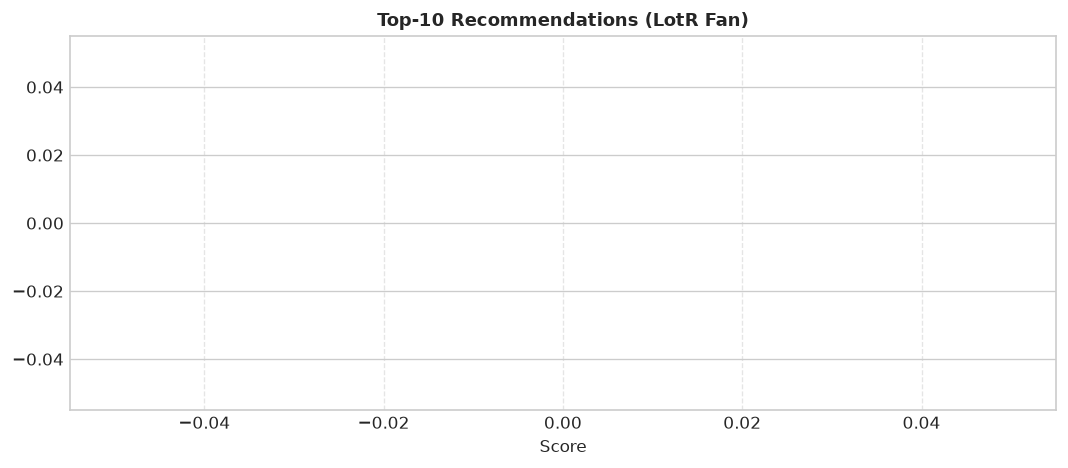

In [17]:
lotr_title = "Lord of the Rings: The Fellowship of the Ring, The (2001)"
lotr_id = title_to_id[lotr_title]
r_dummy = 5.0

# Fold-in updates for dummy user with 1 rating
a_new = 0.0
u_new = np.zeros(emb_dim_p4, dtype=np.float64)
v_lotr = movies_emb_p4[lotr_id]
b_lotr = movies_bias_p4[lotr_id]

for _ in range(5):
    a_new = (lambdda_p4 * (r_dummy - mu - b_lotr - float(np.dot(u_new, v_lotr)))) / (lambdda_p4 + gamma_p4)
    A_new = lambdda_p4 * np.outer(v_lotr, v_lotr) + tau_p4 * np.eye(emb_dim_p4)
    rhs_new = lambdda_p4 * (r_dummy - mu - a_new - b_lotr) * v_lotr
    u_new = np.linalg.solve(A_new, rhs_new)

dots_all = movies_emb_p4 @ u_new

print(f"Dummy User rated '{lotr_title}' = 5.0 stars -> a_new = {a_new:+.4f}, ||u_new||_2 = {np.linalg.norm(u_new):.4f}\n")
print("Top-10 Recommendations (score = u_new^T v_n + 0.05 * b_n, movies with >= 100 ratings):")
print("-" * 100)
scores = dots_all + 0.05 * movies_bias_p4
scores[lotr_id] = -1e9
scores_filtered = np.where(train_movie_counts >= 100, scores, -1e9)
top10_ids = np.argsort(scores_filtered)[::-1][:10]
for rank, mid in enumerate(top10_ids, 1):
    cos_sim = float(np.dot(v_lotr, movies_emb_p4[mid]) / (np.linalg.norm(v_lotr) * np.linalg.norm(movies_emb_p4[mid])))
    print(f"{rank:2d}. {movie_titles[mid]:<55} | Genres: {movie_genres[mid]:<24} | score: {scores[mid]:+.4f} | cos_sim: {cos_sim:+.3f}")

# Polarizing vs Least Polarizing movies (among movies with >= 1,000 training ratings)
norms = np.linalg.norm(movies_emb_p4, axis=1)
well_sampled = np.where(train_movie_counts >= 1000)[0]
most_pol = well_sampled[np.argsort(norms[well_sampled])[::-1][:5]]
least_pol = well_sampled[np.argsort(norms[well_sampled])[:5]]

print("\nTop-5 Most Polarizing Movies (Largest ||v_n||_2, >= 1,000 ratings):")
for rank, mid in enumerate(most_pol, 1):
    print(f"  {rank}. {movie_titles[mid]:<52} | ||v_n||_2 = {norms[mid]:.3f} | Count = {train_movie_counts[mid]:,}")

print("\nTop-5 Least Polarizing Movies (Smallest ||v_n||_2, >= 1,000 ratings):")
for rank, mid in enumerate(least_pol, 1):
    print(f"  {rank}. {movie_titles[mid]:<52} | ||v_n||_2 = {norms[mid]:.3f} | Count = {train_movie_counts[mid]:,}")

fig, ax = plt.subplots(figsize=(9, 4.0))
top_labels = [f"{movie_titles[mid].split('(')[0].replace(', The', '').strip()[:34]} ({movie_genres[mid].split('|')[0]})" for mid in top10_ids[::-1]]
top_vals = [scores[mid] for mid in top10_ids[::-1]]
ax.barh(top_labels, top_vals, color="#2980b9", edgecolor="black", alpha=0.85)
ax.set_xlabel("Score")
ax.set_title("Top-10 Recommendations (LotR Fan)", fontsize=11, fontweight="bold")
ax.grid(True, axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

---
# Practical 5: Feature-Based Model (Movie Genres)

### 5.1 Genre Metadata CSR Representation and 3-Step Genre-ALS Implementation
We encode the movie genre metadata from `movies.csv` into a CSR structure and implement the 3-step ALS updates for user parameters $(a_u, u_u)$, movie parameters $(b_i, v_i)$ with genre prior $\bar{f}_i = |\mathcal{G}_i|^{-1/2} \sum_{g \in \mathcal{G}_i} f_g$, and genre trait vectors $f_g \in \mathbb{R}^K$.

In [18]:
# Build genre vocabulary and movie-to-genre CSR structure
all_genres_set = set()
parsed_movie_genres = []
for g_str in movie_genres:
    gs = [g.strip() for g in g_str.split("|") if g.strip()]
    if not gs:
        gs = ["(no genres listed)"]
    parsed_movie_genres.append(gs)
    all_genres_set.update(gs)

genre_names = sorted(all_genres_set)
genre_to_id = {g: i for i, g in enumerate(genre_names)}
n_genres = len(genre_names)

m_genre_offsets = np.zeros(n_movies + 1, dtype=np.int32)
m_genre_ids_list = []
m_inv_sqrt_G = np.zeros(n_movies, dtype=np.float64)

B_dense = np.zeros((n_movies, n_genres), dtype=np.float64)
for m in range(n_movies):
    g_ids = [genre_to_id[g] for g in parsed_movie_genres[m]]
    m_genre_ids_list.extend(g_ids)
    m_genre_offsets[m + 1] = len(m_genre_ids_list)
    w = 1.0 / np.sqrt(len(g_ids))
    m_inv_sqrt_G[m] = w
    for gid in g_ids:
        B_dense[m, gid] = w

m_genre_ids = np.array(m_genre_ids_list, dtype=np.int32)
BtB = B_dense.T @ B_dense
print(f"Encoded {n_genres} genres across {n_movies:,} movies.")


@njit(parallel=True, fastmath=True)
def update_movies_genre_numba(movies_bias: np.ndarray, movies_emb: np.ndarray,
                              users_bias: np.ndarray, users_emb: np.ndarray,
                              genre_emb: np.ndarray,
                              m_offsets: np.ndarray, m_users: np.ndarray, m_ratings: np.ndarray,
                              g_offsets: np.ndarray, g_ids: np.ndarray, inv_sqrt_G: np.ndarray,
                              mu: float, lambdda: float, gamma: float, tau: float) -> None:
    n_m = len(m_offsets) - 1
    k = movies_emb.shape[1]

    for m in prange(n_m):
        start = m_offsets[m]
        end = m_offsets[m + 1]
        count = end - start

        # Genre prior centroid f_bar_m
        f_bar = np.zeros(k, dtype=np.float64)
        w = inv_sqrt_G[m]
        for g_idx in range(g_offsets[m], g_offsets[m + 1]):
            gid = g_ids[g_idx]
            for d in range(k):
                f_bar[d] += w * genre_emb[gid, d]

        if count == 0:
            movies_bias[m] = 0.0
            for d in range(k):
                movies_emb[m, d] = f_bar[d]
            continue

        # 1. Movie bias update
        sum_res = 0.0
        for idx in range(start, end):
            u = m_users[idx]
            dot = 0.0
            for d in range(k):
                dot += users_emb[u, d] * movies_emb[m, d]
            sum_res += m_ratings[idx] - mu - users_bias[u] - dot
        bm = (lambdda * sum_res) / (lambdda * count + gamma)
        movies_bias[m] = bm

        # 2. Movie trait vector update with genre prior
        A = np.zeros((k, k), dtype=np.float64)
        b = np.zeros(k, dtype=np.float64)
        for d in range(k):
            A[d, d] = tau
            b[d] = tau * f_bar[d]

        for idx in range(start, end):
            u = m_users[idx]
            r_res = lambdda * (m_ratings[idx] - mu - bm - users_bias[u])
            for d1 in range(k):
                uu1 = users_emb[u, d1]
                b[d1] += r_res * uu1
                l_uu1 = lambdda * uu1
                for d2 in range(d1 + 1):
                    A[d1, d2] += l_uu1 * users_emb[u, d2]

        _cholesky_solve_inplace(A, b, movies_emb[m])


def update_genre_emb(movies_emb: np.ndarray, B_mat: np.ndarray, BtB_mat: np.ndarray,
                     tau: float, tau_f: float) -> np.ndarray:
    G = BtB_mat.shape[0]
    lhs = tau * BtB_mat + tau_f * np.eye(G, dtype=np.float64)
    rhs = tau * (B_mat.T @ movies_emb)
    return np.linalg.solve(lhs, rhs)

Encoded 20 genres across 84,432 movies.


### 5.2 Training the Genre-ALS Model
We train the Genre-ALS model with $K = 16$ ($\lambda = 1.0, \gamma = 0.1, \tau = 5.0, \tau_f = 1.0$) for $12$ iterations.

In [19]:
emb_dim_p5 = 16
lambdda_p5 = 1.0
gamma_p5 = 0.1
tau_p5 = 5.0
tau_f_p5 = 1.0
n_iters_p5 = 12

users_emb_p5, users_bias_p5, movies_emb_p5, movies_bias_p5 = init_pmf_params(
    n_users, n_movies, emb_dim=emb_dim_p5, tau=tau_p5
)
genre_emb_p5 = np.zeros((n_genres, emb_dim_p5), dtype=np.float64)

p5_loss_hist, p5_tr_rmse, p5_te_rmse = [], [], []

for it in range(1, n_iters_p5 + 1):
    t_ep = time.perf_counter()
    # Step 1: Update users
    update_entities_numba(users_bias_p5, users_emb_p5, movies_bias_p5, movies_emb_p5,
                          train_data["users_offsets"], train_data["users_movies"], train_data["users_ratings"],
                          mu, lambdda_p5, gamma_p5, tau_p5)
    # Step 2: Update movies with genre prior
    update_movies_genre_numba(movies_bias_p5, movies_emb_p5, users_bias_p5, users_emb_p5, genre_emb_p5,
                              train_data["movies_offsets"], train_data["movies_users"], train_data["movies_ratings"],
                              m_genre_offsets, m_genre_ids, m_inv_sqrt_G,
                              mu, lambdda_p5, gamma_p5, tau_p5)
    # Step 3: Update genre embeddings
    genre_emb_p5 = update_genre_emb(movies_emb_p5, B_dense, BtB, tau_p5, tau_f_p5)
    ep_sec = time.perf_counter() - t_ep

    nll, base_loss, tr_r = compute_metrics_numba(
        users_bias_p5, users_emb_p5, movies_bias_p5, movies_emb_p5,
        train_data["users_offsets"], train_data["users_movies"], train_data["users_ratings"],
        mu, lambdda_p5, gamma_p5, tau_p5
    )
    # Replace standard movie L2 penalty with ||V - B F||_F^2 + tau_f ||F||_F^2
    f_bar_all = B_dense @ genre_emb_p5
    genre_loss = (base_loss - 0.5 * tau_p5 * float(np.sum(movies_emb_p5 ** 2))
                  + 0.5 * tau_p5 * float(np.sum((movies_emb_p5 - f_bar_all) ** 2))
                  + 0.5 * tau_f_p5 * float(np.sum(genre_emb_p5 ** 2)))
    te_r = compute_test_rmse_numba(users_bias_p5, users_emb_p5, movies_bias_p5, movies_emb_p5,
                                  test_data["users_ids"], test_data["users_movies"], test_data["users_ratings"], mu)

    p5_loss_hist.append(genre_loss)
    p5_tr_rmse.append(tr_r)
    p5_te_rmse.append(te_r)
    print(f"Iter {it:2d} | Genre Loss: {genre_loss:13,.2f} | Train RMSE: {tr_r:.4f} | Test RMSE: {te_r:.4f} ({ep_sec:.2f}s)")

Iter  1 | Genre Loss:  8,773,558.76 | Train RMSE: 0.8169 | Test RMSE: 0.8843 (5.55s)
Iter  2 | Genre Loss:  7,315,932.76 | Train RMSE: 0.7347 | Test RMSE: 0.8313 (3.31s)
Iter  3 | Genre Loss:  6,793,777.23 | Train RMSE: 0.7054 | Test RMSE: 0.8066 (3.28s)
Iter  4 | Genre Loss:  6,550,561.48 | Train RMSE: 0.6919 | Test RMSE: 0.7951 (3.22s)
Iter  5 | Genre Loss:  6,418,601.88 | Train RMSE: 0.6848 | Test RMSE: 0.7895 (3.25s)
Iter  6 | Genre Loss:  6,337,975.81 | Train RMSE: 0.6807 | Test RMSE: 0.7865 (3.32s)
Iter  7 | Genre Loss:  6,283,602.45 | Train RMSE: 0.6780 | Test RMSE: 0.7847 (3.22s)
Iter  8 | Genre Loss:  6,244,000.08 | Train RMSE: 0.6761 | Test RMSE: 0.7836 (3.26s)
Iter  9 | Genre Loss:  6,213,588.76 | Train RMSE: 0.6747 | Test RMSE: 0.7828 (3.29s)
Iter 10 | Genre Loss:  6,189,468.45 | Train RMSE: 0.6736 | Test RMSE: 0.7822 (3.26s)
Iter 11 | Genre Loss:  6,169,972.59 | Train RMSE: 0.6727 | Test RMSE: 0.7817 (3.28s)
Iter 12 | Genre Loss:  6,154,023.70 | Train RMSE: 0.6720 | Test R

### 5.3 Plotting Genre-ALS Convergence and 2D Genre Embeddings
We train a $K = 2$ Genre-ALS model to visualize the 2D genre vectors $f_g \in \mathbb{R}^2$, and plot the Genre-ALS convergence curves alongside the 2D genre map.

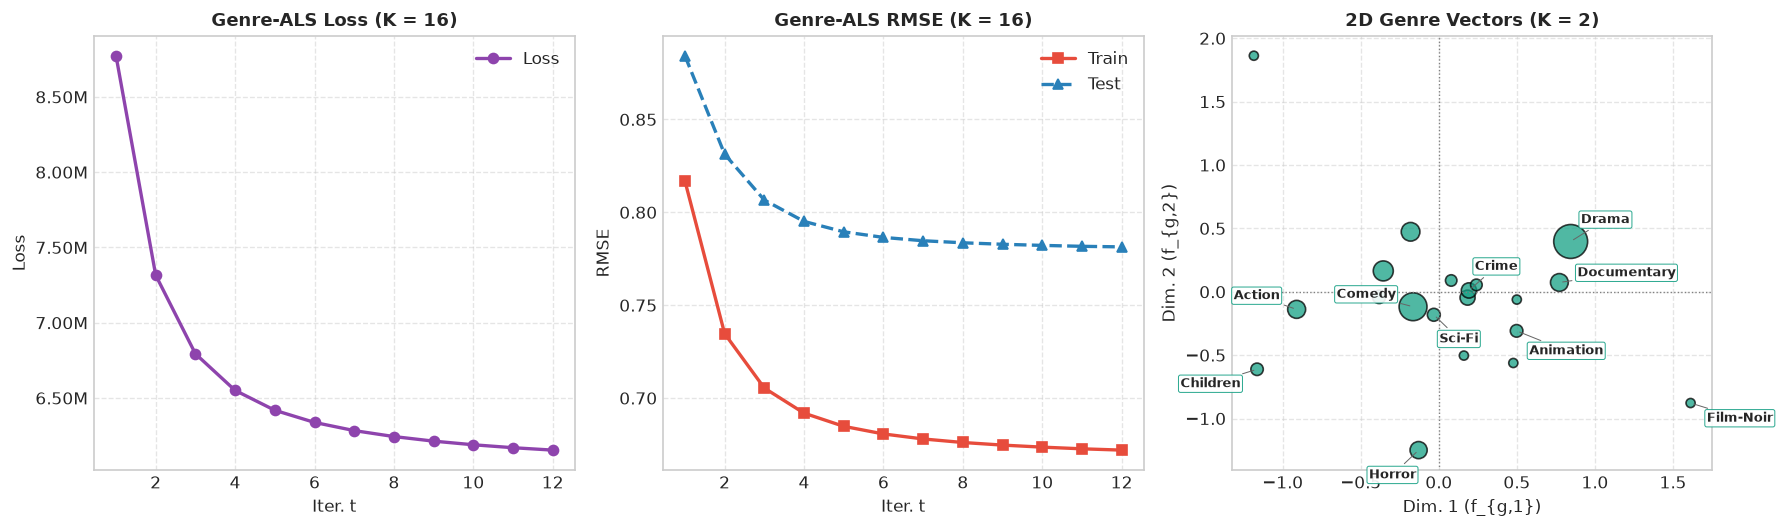

In [20]:
# Train K=2 Genre-ALS model for 2D genre plot
u_emb_g2, u_bias_g2, m_emb_g2, m_bias_g2 = init_pmf_params(n_users, n_movies, emb_dim=2, tau=5.0)
g_emb_2d = np.zeros((n_genres, 2), dtype=np.float64)
for _ in range(15):
    update_entities_numba(u_bias_g2, u_emb_g2, m_bias_g2, m_emb_g2,
                          train_data["users_offsets"], train_data["users_movies"], train_data["users_ratings"],
                          mu, 1.0, 0.1, 5.0)
    update_movies_genre_numba(m_bias_g2, m_emb_g2, u_bias_g2, u_emb_g2, g_emb_2d,
                              train_data["movies_offsets"], train_data["movies_users"], train_data["movies_ratings"],
                              m_genre_offsets, m_genre_ids, m_inv_sqrt_G,
                              mu, 1.0, 0.1, 5.0)
    g_emb_2d = update_genre_emb(m_emb_g2, B_dense, BtB, 5.0, 1.0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
iters_p5 = np.arange(1, len(p5_loss_hist) + 1)

axes[0].plot(iters_p5, p5_loss_hist, marker='o', linewidth=2, color="#8e44ad", label="Loss")
axes[0].set_title(f"Genre-ALS Loss (K = {emb_dim_p5})", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Iter. t")
axes[0].set_ylabel("Loss")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x*1e-6:.2f}M'))
axes[0].legend(frameon=False)
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(iters_p5, p5_tr_rmse, marker='s', linewidth=2, color="#e74c3c", label="Train")
axes[1].plot(iters_p5, p5_te_rmse, marker='^', linestyle="--", linewidth=2, color="#2980b9", label="Test")
axes[1].set_title(f"Genre-ALS RMSE (K = {emb_dim_p5})", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Iter. t")
axes[1].set_ylabel("RMSE")
axes[1].legend(frameon=False)
axes[1].grid(True, linestyle="--", alpha=0.5)

genre_Support = np.sum(B_dense > 0, axis=0)
axes[2].scatter(g_emb_2d[:, 0], g_emb_2d[:, 1], s=np.maximum(genre_Support / 80, 30),
                color="#16a085", alpha=0.75, edgecolors="black")
key_genres = {"Drama", "Crime", "Film-Noir", "Documentary", "Sci-Fi", "Action", "Horror", "Children", "Animation", "Comedy"}
for gid, gname in enumerate(genre_names):
    if gname in key_genres:
        axes[2].annotate(gname, (g_emb_2d[gid, 0], g_emb_2d[gid, 1]),
                         xytext=(4, 4), textcoords="offset points", fontsize=8.0, fontweight="bold")
axes[2].axhline(0, color="gray", linestyle=":", linewidth=0.8)
axes[2].axvline(0, color="gray", linestyle=":", linewidth=0.8)
axes[2].set_title("2D Genre Vectors (K = 2)", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Dim. 1 (f_{g,1})")
axes[2].set_ylabel("Dim. 2 (f_{g,2})")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()